# Where does the network look? Grad-CAM on echo image quality

In the ML-DL introduction notebook (`mldl-introduction.ipynb`) we fine-tuned a ResNet-18 that labels an echocardiographic frame as `Poor` or `Good`, and we measured *how often* it is right. An accuracy value, however, does not tell us *what* the decision is based on: a network can be right for the wrong reasons, for example by relying on a detail that happens to go together with the label in the training images.

In this notebook we ask: **which regions of the image drive the quality label?** The label describes the ultrasound image (e.g., how clearly the walls of the heart can be seen), so we expect the evidence to lie inside the **sector**, i.e., the fan-shaped region where the image is formed. Outside the sector the frame is black and carries no information.

To answer, we use **Grad-CAM** (Section 2), a method that turns one prediction of the network into a **heatmap**: a colour map, laid over the image, that highlights the regions that speak in favour of a class. We will:

1. **Look**: compute the heatmaps of a few validation images (Section 3);
2. **Check**: compare them with the heatmaps of the same network before fine-tuning (Section 3);
3. **Measure**: quantify how much of each heatmap lies inside the sector, over the whole validation set (Section 4).

**Before starting**, run `mldl-introduction.ipynb`: this notebook reuses the data cache (`camus_poor_good_224.npz`) and the weights of the fine-tuned model (`models/best_model.pth`) that it saves in its output folder.

## 0. Setup

In [ ]:
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights
from scipy import ndimage
from sklearn.metrics import balanced_accuracy_score

IN_KAGGLE = bool(os.environ.get("KAGGLE_URL_BASE", ""))

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("Kaggle:", IN_KAGGLE, "| Device:", DEVICE)

In [ ]:
# Kaggle: attach the output of your mldl-introduction notebook (+ Add Input > Your Work) and update this path
KAGGLE_ROOT = Path("/kaggle/input/notebooks/riccardogibello11/dl-introduction")
# Local runs: type the output folder of mldl-introduction.ipynb (its OUTPUT_ROOT) when asked.
# input() needs an interactive session, so it is not called on Kaggle
if not IN_KAGGLE:
    LOCAL_ROOT = Path(
        input("Output folder of mldl-introduction.ipynb: ").strip().strip("'\"")
    ).expanduser()

In [ ]:
ROOT = KAGGLE_ROOT if IN_KAGGLE else LOCAL_ROOT
CACHE = ROOT / "camus_poor_good_224.npz"
MODEL_PATH = ROOT / "models" / "best_model.pth"
for p in [CACHE, MODEL_PATH]:
    if not p.exists():
        raise FileNotFoundError(
            f"{p} not found: run mldl-introduction.ipynb first, or update the paths above"
        )

## 1. Data and model

The helpers below are the same as in the ML-DL notebook (`to_model_input` in Section 2, `build_resnet18` in Section 4.2), reduced to the image-only case. We load the validation set and the fine-tuned model, and check that the balanced accuracy matches the one of the ML-DL notebook. As there, the test set stays untouched: all the analyses below use validation images only.

In [ ]:
CLASSES = ["Poor", "Good"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
IM_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IM_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def to_model_input(imgs_u8):
    # imgs_u8: (B, H, W) uint8  ->  (B, 3, H, W) float, normalized with the ImageNet statistics
    x = torch.from_numpy(imgs_u8).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
    return (x - IM_MEAN) / IM_STD


def build_resnet18(n_classes=len(CLASSES)):
    # ImageNet weights, with a new last layer (fc) for our classes
    m = resnet18(weights=ResNet18_Weights.DEFAULT)
    m.fc = nn.Linear(m.fc.in_features, n_classes)
    return m


with np.load(CACHE) as z:
    val = {k: z[f"val_{k}"] for k in ("x", "mask", "y", "patient")}
print(
    f"Validation: {len(val['y'])} images, {np.bincount(val['y']).tolist()} for {CLASSES}"
)

model_ft = build_resnet18().to(DEVICE)
model_ft.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model_ft.eval()

with torch.no_grad():
    x_val = to_model_input(val["x"]).to(DEVICE)
    p_val = model_ft(x_val).softmax(1).cpu().numpy()  # class probabilities
val_pred = p_val.argmax(1)
print(
    f"Validation balanced accuracy: {balanced_accuracy_score(val['y'], val_pred):.3f} (it should match the ML-DL notebook)"
)

## 2. Grad-CAM in four steps

**Grad-CAM** (Gradient-weighted Class Activation Mapping, [Selvaraju et al., 2017](https://arxiv.org/abs/1610.02391)) explains one prediction with a heatmap. It combines two ideas from the ML-DL notebook:

- **Feature maps.** Each feature map is the response of one learned filter, and it keeps the layout of the image: a high value at one position means that the pattern of that filter is present *there*.
- **Gradient.** The gradient tells how much a number computed by the network changes when one of its inputs changes slightly. During training we used the gradient of the loss with respect to the weights; here we use the gradient of a class score with respect to the feature maps. It is computed by the same backpropagation, and no weight is changed.

Grad-CAM uses the gradient to decide **how much** each feature map matters for a class, and the feature map itself to tell **where** it is active. The figure below shows the idea on a natural photo.

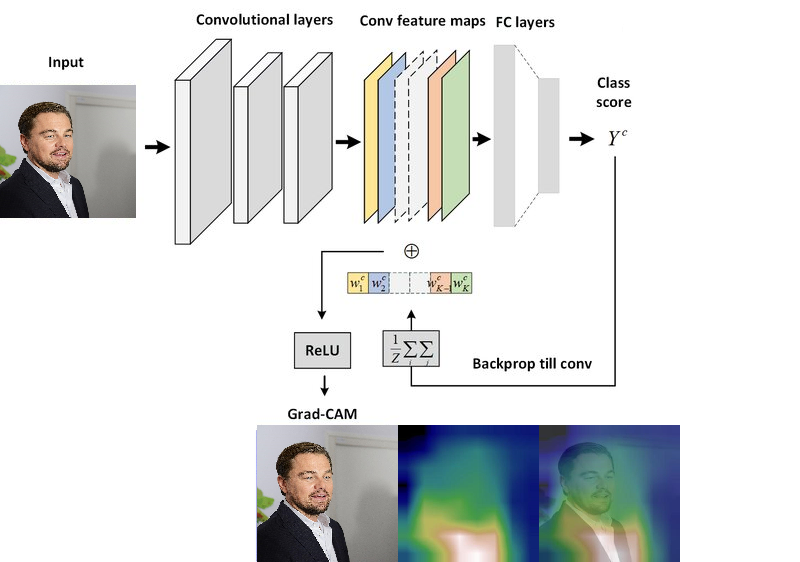

*Grad-CAM on a natural photo. The class score $Y^c$ is backpropagated down to the feature maps of the last convolutional layer, and the gradients are averaged over the $Z$ positions of each map ($\frac{1}{Z}\sum_i\sum_j$), giving one weight per map (called $w_k^c$ in the figure, $\alpha_k^c$ below). The weighted sum of the maps ($\oplus$) then goes through a ReLU, which keeps only the positive values. Source: adapted from TomMarine, [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:CAM_and_Grad-CAM_example.png), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/), cropped to the Grad-CAM path.*

In our ResNet-18, the last convolutional block, `layer4`, outputs $K = 512$ feature maps $A^k$ of $7 \times 7$ cells. Each cell corresponds to a $32 \times 32$ patch of the $224 \times 224$ input, because the network halves the resolution five times ($224 / 2^5 = 7$). The network then averages each map into a single number (global average pooling), and the `fc` layer combines the 512 averages into one **score** per class, $y^c$: the higher the score of a class relative to the other, the higher its probability.

Grad-CAM computes the heatmap of class $c$ in four steps:

1. **Forward pass.** Run the image through the network and keep the feature maps $A^k$ of `layer4`.
2. **Weights.** Backpropagate the score $y^c$ down to `layer4`, i.e., compute its gradient with respect to every cell of every map, and average the gradient over the 49 cells of each map. The result is one weight $\alpha_k^c$ per map: positive if strengthening map $k$ raises the score of class $c$, negative if it lowers it.
3. **Weighted sum.** Sum the maps, each multiplied by its weight, and keep only the positive values with a ReLU (it sets the negative values to zero). The result is a $7 \times 7$ map, high where the patterns that favour class $c$ are active.
4. **Enlarge.** Resize the $7 \times 7$ map to $224 \times 224$ with bilinear interpolation (each pixel is a weighted average of the four nearest cells), and lay it over the image.

In formulas, with $i, j$ the row and the column of a cell:

$$\alpha_k^c = \frac{1}{49} \sum_{i,j} \frac{\partial y^c}{\partial A^k_{ij}}, \qquad L^c = \mathrm{ReLU}\Big(\sum_{k=1}^{512} \alpha_k^c A^k\Big).$$

<img src="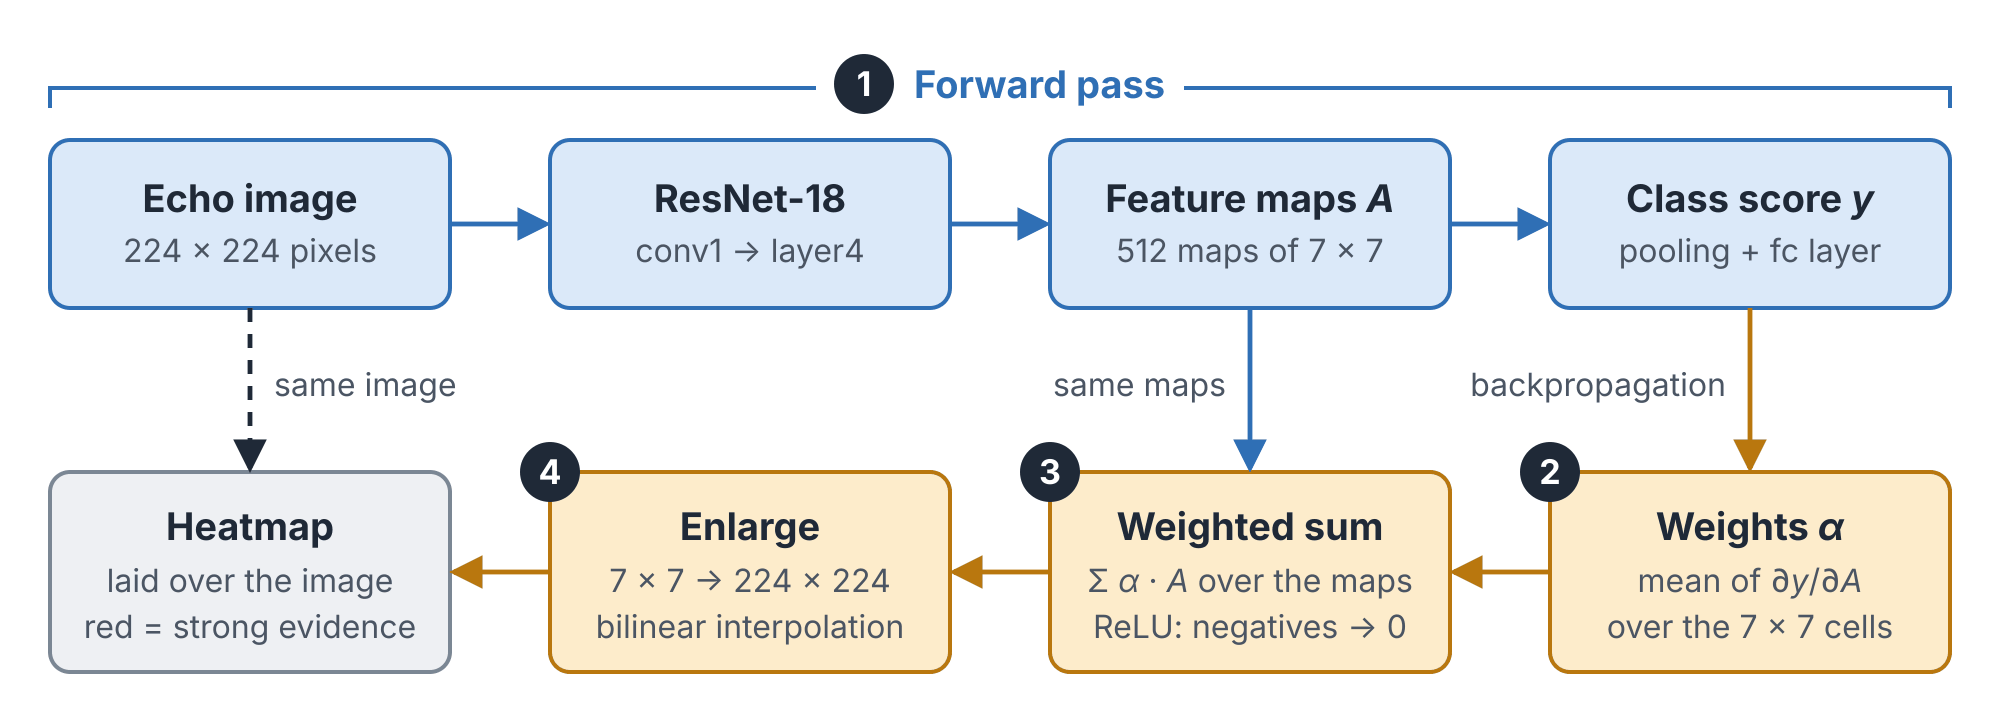" alt="Grad-CAM in four steps. Top row, step 1, forward pass: the echo image (224 x 224 pixels) goes through ResNet-18 up to layer4, which outputs 512 feature maps A of 7 x 7; pooling and the fc layer give the class score y. Bottom row, from right to left: step 2, backpropagation of y gives one weight alpha per map, the mean of the gradient over its 7 x 7 cells; step 3, weighted sum of the same feature maps, followed by a ReLU that sets the negative values to 0; step 4, the 7 x 7 map is enlarged to 224 x 224 by bilinear interpolation. The result is the heatmap, laid over the same image." width="800" style="background-color:white; padding:8px">

*Grad-CAM on our ResNet-18, with the four steps listed above: blue arrows are the usual forward pass, orange arrows are the Grad-CAM computations. Figure created with AI assistance.*

In [ ]:
def grad_cam(model, x, layer, class_idx):
    """
    Computes the Grad-CAM maps of `layer` for a batch of images.

    Args:
        model: the network (it is switched to evaluation mode).
        x: model input of shape (B, 3, H, W).
        layer: the block whose feature maps are used (e.g., model.layer4).
        class_idx: one class for all the images (int), or one class per image (array of B ints).

    Returns:
        np.ndarray: maps of shape (B, H, W), non-negative, in arbitrary units
            (0: no evidence in favour of the class).
    """
    store = {}
    # Hook: store the feature maps of `layer` during the forward pass (step 1)
    hook = layer.register_forward_hook(
        lambda module, inputs, output: store.update(a=output),
    )
    model.eval()
    try:
        scores = model(x)
    finally:
        hook.remove()
    a = store["a"]  # (B, K, h, w), e.g., K=512 maps of 7 x 7 for layer4
    target = torch.as_tensor(class_idx, device=scores.device).expand(len(x))
    # Step 2: gradient of each image's class score with respect to its feature maps
    # (in evaluation mode the images of a batch do not interact, so their scores can be summed)
    (g,) = torch.autograd.grad(
        scores.gather(
            1,
            target[:, None],  # get the score of the target class for each image (B, 1)
        ).sum(),  # sum of the scores of the target class for all images
        a,
    )  # (B, K, h, w) gradients of the target class score w.r.t. the feature maps
    w = g.mean(dim=(2, 3), keepdim=True)  # (B, K, 1, 1)
    # Step 3: weighted sum, keeping only the evidence in favour of the class
    cam = F.relu((w * a).sum(dim=1, keepdim=True))
    # Step 4: back to the image size
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
    return cam[:, 0].detach().cpu().numpy()

## 3. Looking at four validation images

We pick one validation image for each possible outcome: a `Poor` frame classified as `Poor`, a `Good` frame classified as `Good`, and the two kinds of error. Each image comes from a different patient.

For each image we compute the map of the class `Poor` and the map of the class `Good`. The last column is a **sanity check**, a variant of the model-randomisation test of [Adebayo et al. (2018)](https://arxiv.org/abs/1810.03292): the same computation, for the class predicted by the fine-tuned network, on the network *before* fine-tuning, i.e., with the ImageNet weights and a new, untrained `fc` layer. That network has learned nothing about image quality: if its maps looked like those of the fine-tuned network, the maps would reflect the content of the image (e.g., where the bright structures are), not what the network has learned.

In [ ]:
POOR, GOOD = CLASS_TO_IDX["Poor"], CLASS_TO_IDX["Good"]
cases = {
    "Poor, predicted Poor": (val["y"] == POOR) & (val_pred == POOR),
    "Good, predicted Good": (val["y"] == GOOD) & (val_pred == GOOD),
    "Poor, predicted Good": (val["y"] == POOR) & (val_pred == GOOD),
    "Good, predicted Poor": (val["y"] == GOOD) & (val_pred == POOR),
}
rng = np.random.default_rng(SEED)
shown, used_patients = [], set()  # shown: (case, image index)
for case, sel in cases.items():
    # A random image of this case, from a patient that is not shown yet
    candidates = [
        i
        for i in rng.permutation(np.flatnonzero(sel))
        if val["patient"][i] not in used_patients
    ]
    if candidates:
        shown.append((case, candidates[0]))
        used_patients.add(val["patient"][candidates[0]])
ids = [i for _, i in shown]
x = x_val[ids]

# Sanity check: the same network before fine-tuning (ImageNet weights, new untrained fc)
torch.manual_seed(SEED)
model_init = build_resnet18().to(DEVICE).eval()

maps = {c: grad_cam(model_ft, x, model_ft.layer4, CLASS_TO_IDX[c]) for c in CLASSES}
maps_init = grad_cam(model_init, x, model_init.layer4, val_pred[ids])

fig, axes = plt.subplots(len(ids), 4, figsize=(13, 3.4 * len(ids)), squeeze=False)
for row, (case, i) in enumerate(shown):
    panels = [
        (None, f"{case}\np(Poor) = {p_val[i, POOR]:.2f}"),
        (maps["Poor"][row], "Grad-CAM, class Poor"),
        (maps["Good"][row], "Grad-CAM, class Good"),
        (maps_init[row], f"Before fine-tuning, class {CLASSES[val_pred[i]]}"),
    ]
    # The two classes share one colour scale, so that a weak map also looks weak
    vmax = max(maps["Poor"][row].max(), maps["Good"][row].max(), 1e-12)
    for col, (ax, (cam, title)) in enumerate(zip(axes[row], panels)):
        ax.imshow(val["x"][i], cmap="gray")
        if cam is not None:
            scale = vmax if col < 3 else max(cam.max(), 1e-12)
            ax.imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=scale)
        # Manual masks (LV cavity, myocardium, atrium), only as an anatomical reference
        ax.contour(val["mask"][i], levels=[0.5, 1.5, 2.5], colors="w", linewidths=0.6)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
plt.tight_layout()
plt.show()

**How to read the figure.** The colour goes from dark blue (no evidence in favour of the class) to red (strongest evidence). In each row the two classes share one colour scale, so a weak map also looks weak; the last column has its own scale. The white contours are the manual masks of the LV cavity, the myocardium and the left atrium: they are only an anatomical reference, and the network never saw them.

Keep in mind two points from Section 2:

- a dark-blue map does not mean that the network ignores the image: there, the evidence may be *against* the class, and the ReLU set it to zero (e.g., the `Poor` map of a frame confidently predicted `Good`);
- the probability depends on the *difference* between the two scores, so read the two maps of a row together.

Now compare the fine-tuned maps with the last column: do they highlight the same regions? Which ones fall inside the sector, and which on the black corners? Section 4 answers with numbers instead of impressions.

## 4. Is the evidence inside the sector?

Four images are not enough to draw conclusions, and the eye is easily fooled, so we **measure**. For every validation image we compute the map of the class predicted by the fine-tuned network, and the share of the map (the sum of its values) that lies inside the sector. We repeat the measurement on the network before fine-tuning, for the same classes.

The sector is found from the image itself, since the pixels outside it are exactly black: we keep the non-black pixels, close the small dark gaps inside the fan with a morphological closing (a dilation followed by an erosion), fill the remaining holes, and keep the largest connected region. As always with an automatic mask, check the result on an image.

In [ ]:
def sector_mask(img, pad=16):
    # img: (H, W) uint8  ->  (H, W) bool, True inside the ultrasound sector
    # The fan touches the image border, where the erosion would shrink it: pad with black first
    fan = np.pad(img > 0, pad)
    fan = ndimage.binary_closing(
        fan, structure=np.ones((9, 9)), iterations=2
    )  # fill small dark gaps
    fan = ndimage.binary_fill_holes(fan[pad:-pad, pad:-pad])
    labels, _ = ndimage.label(fan)
    return (
        labels == np.bincount(labels.ravel())[1:].argmax() + 1
    )  # largest connected region


sectors = np.stack([sector_mask(img) for img in val["x"]])

plt.figure(figsize=(4, 4))
plt.imshow(val["x"][ids[0]], cmap="gray")
plt.contour(sectors[ids[0]], levels=[0.5], colors="r")
plt.title("Sector found automatically")
plt.axis("off")
plt.show()

In [ ]:
def share_inside_sector(model, bs=32):
    # Share of each map (class predicted by the fine-tuned network) that lies inside the sector
    shares = []
    for s in range(0, len(x_val), bs):
        cam = grad_cam(model, x_val[s : s + bs], model.layer4, val_pred[s : s + bs])
        inside = (cam * sectors[s : s + bs]).sum(axis=(1, 2))
        shares.append(inside / np.maximum(cam.sum(axis=(1, 2)), 1e-12))
    return np.concatenate(shares)


print(f"Sector area: {sectors.mean():.2f} of the image")
for name, model in [("Fine-tuned", model_ft), ("Before fine-tuning", model_init)]:
    share = share_inside_sector(model)
    print(
        f"{name:20s} share of the map inside the sector: mean {share.mean():.2f} | "
        f"images with most of the map outside: {(share < 0.5).mean():.0%}"
    )

**Reading the numbers.** Compare each mean share with the sector area: a map spread uniformly over the image would get a share equal to the area, so only a clearly higher share means that the evidence is concentrated inside the sector. Is the share also higher than for the network before fine-tuning? Note that the share can hardly reach 1, even when all the evidence is inside the sector: each cell covers a 32 x 32 patch, and the enlargement blends the cells along the border of the sector with their neighbours outside it.

## 5. Extensions and limitations

### Grad-CAM for regression

Grad-CAM needs only one number to differentiate. In classification it is the score of a class, but any number computed by the network works, for example the output of a **regression** network that estimates a continuous value, such as the LV volume. The function `grad_cam_regression` below does this for a network with a single output. It is not used in this notebook: apply it to your own regression model.

In [ ]:
def grad_cam_regression(model, x, layer, signed=False):
    """
    Computes Grad-CAM maps for a single-output regression model.

    Args:
        model: the network (switched to evaluation mode).
        x: model input of shape (B, 3, H, W).
        layer: target convolutional block (e.g., model.layer4).
        signed: if True, skips the ReLU, to show both the regions that increase (+)
                and those that decrease (-) the predicted value.

    Returns:
        np.ndarray: maps of shape (B, H, W).
    """
    store = {}
    hook = layer.register_forward_hook(
        lambda module, inputs, output: store.update(a=output)
    )
    model.eval()
    try:
        preds = model(x)  # Shape: (B, 1) or (B,)
    finally:
        hook.remove()

    a = store["a"]  # (B, K, h, w)

    # Gradient of the predicted scalar with respect to the feature maps
    (g,) = torch.autograd.grad(preds.sum(), a)
    w = g.mean(dim=(2, 3), keepdim=True)
    cam = (w * a).sum(dim=1, keepdim=True)

    if not signed:
        cam = F.relu(cam)

    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
    return cam[:, 0].detach().cpu().numpy()

Compared with `grad_cam`, two things change:

- **No class index.** The network has a single output, and that is the number we differentiate.
- **Optional sign.** With `signed=True` the ReLU is skipped: positive values mark the regions that raise the predicted value, negative values those that lower it. Show such a map with a diverging colour map, i.e., two colours for the two signs and white at zero (e.g., `cmap="RdBu_r"` with `vmin=-m, vmax=m`, where `m` is the largest absolute value of the map).

There is only one map per image, so there is no other class to compare it with, as we did in Section 3. The map can still serve as a sanity check of a regression model: the sector test of Section 4 applies unchanged, since a network that estimates the LV volume should not rely on the black corners. If the network ends like ours (global average pooling and one linear output) and you use `layer4`, the identity of Section 2 holds too: the prediction is the sum of the cells of the signed map, before enlarging, plus the bias.

### Limitations

Grad-CAM is a useful check, but a heatmap is easy to over-interpret:

- **Coarse.** The map tells roughly *where* the evidence is, at the resolution of 32 x 32 pixels, not *which structure* (wall, cavity, valve) nor *which property* (blurred borders, noise in the cavity) the network uses. Moreover, each cell of `layer4` is computed from a region of the image much larger than its patch, so a red cell means "around here", not "exactly here".
- **Position.** The frames are apical views (the probe is placed over the apex of the heart), so the ventricle is almost always in the same place. In images predicted `Poor` and in images predicted `Good` alike, the evidence often sits on the ventricle, but a blob in the middle of the image would land on it anyway: this alone does not prove that the network has "found" the ventricle.
- **One model, one image.** A map explains one prediction of one model. It is not a validation of the model, and a red region is not a clinical finding.
- **Layer choice.** Try `model_ft.layer3` (maps of 14 x 14) in the cells above: the maps are finer, but noisier and less specific to the class, and the score is no longer the sum of the cells (Section 2).

**Possible extension.** *Occlusion sensitivity* ([Zeiler and Fergus, 2014](https://arxiv.org/abs/1311.2901)) hides one part of the image at a time and records how the class score changes. It is slower, but it tests directly whether a region matters for the decision.

**References**

- R. R. Selvaraju et al., *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization*, ICCV 2017. https://arxiv.org/abs/1610.02391
- B. Zhou et al., *Learning Deep Features for Discriminative Localization* (CAM), CVPR 2016. https://arxiv.org/abs/1512.04150
- J. Adebayo et al., *Sanity Checks for Saliency Maps*, NeurIPS 2018. https://arxiv.org/abs/1810.03292
- M. D. Zeiler and R. Fergus, *Visualizing and Understanding Convolutional Networks*, ECCV 2014. https://arxiv.org/abs/1311.2901
- *pytorch-grad-cam*, a library with Grad-CAM and many of its variants (Grad-CAM++, Score-CAM, ...): https://github.com/jacobgil/pytorch-grad-cam